**TP1 - Exercice 2 : Classification - Prédire la survie sur le Titanic**


*  *Module :* Technologies IA
*  *Filière :* Ingénierie Logicielle et Intelligence Artificielle (ILIA2)

*   *Réalisé par :* BOUZIANE WARITINI Safae    N° : 8


**Introduction et Objectif :**

Contrairement à l'exercice précédent qui faisait de la régression, cet exercice aborde un problème de **classification binaire**. L'objectif est de prédire si un passager a survécu ($1$) ou non ($0$) au naufrage du Titanic à partir de ses caractéristiques socio-démographiques et financières.   

**Étape 1 : Chargement et Exploration des données**

Cette étape consiste à charger le jeu de données depuis un fichier CSV, à examiner sa structure globale et à détecter la présence de valeurs manquantes (ce qui est très fréquent sur le dataset du Titanic).

In [1]:
import pandas as pd

# Chargement du dataset
url = "https://raw.githubusercontent.com/SafaeBouzianeWaritini/TP-Technologies-IA/refs/heads/main/TP1-Technologies-IA/train.csv"
data = pd.read_csv(url)

# 1. Aperçu des premières lignes
print("=== 5 premières lignes ===")
display(data.head())

# 2. Informations sur les types de variables
print("\n=== Informations structurelles ===")
data.info()

# 3. Décompte des valeurs manquantes
print("\n=== Valeurs manquantes ===")
print(data.isnull().sum())

=== 5 premières lignes ===


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



=== Informations structurelles ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

=== Valeurs manquantes ===
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare     

**Étape 2 : Nettoyage et Traitement des données**

**1.   Sélection des colonnes pertinentes :** On ne garde que les variables les plus influentes pour la prédiction (*Survived, Pclass, Sex, Age, SibSp, Parch, Fare, Embarked*).  

**2.  Imputation des valeurs manquantes :**


*   Pour l'âge (*Age*), on remplace les valeurs absentes par la **médiane** pour éviter l'influence des valeurs extrêmes.
*   Pour le port d'embarquement (*Embarked*), on le remplace par le **mode** (la valeur la plus fréquente).


In [2]:
# 1. Sélection des colonnes utiles
data = data[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]

# 2. Imputation de l'âge par la médiane
data['Age'] = data['Age'].fillna(data['Age'].median())

# 3. Imputation du port d'embarquement par le mode
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])

# Vérification qu'il ne reste plus de valeurs manquantes
print(data.isnull().sum())

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


**Étape 3 : Encodage des variables catégorielles**

Les algorithmes de Machine Learning manipulent uniquement des nombres. Les colonnes textuelles comme le sexe (*Sex*) et le port d'embarquement (*Embarked*) doivent être converties en valeurs numériques à l'aide de **LabelEncoder**.

In [3]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

# Conversion du Sexe et de l'embarquement en entiers
data['Sex'] = le.fit_transform(data['Sex'])
data['Embarked'] = le.fit_transform(data['Embarked'])

display(data.head())

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,22.0,1,0,7.2500,2
1,1,1,0,38.0,1,0,71.2833,0
2,1,3,0,26.0,0,0,7.9250,2
3,1,1,0,35.0,1,0,53.1000,2
4,0,3,1,35.0,0,0,8.0500,2


**Étape 4 : Séparation des données (Train / Test Split)**

On sépare la variable cible (*Survived*, notée $y$) des caractéristiques explicatives (**X**), puis on divise le tout en un ensemble d'entraînement (80%) et un ensemble de test (20%).

In [4]:
from sklearn.model_selection import train_test_split

# Séparation Features (X) et Target (y)
X = data.drop('Survived', axis=1)
y = data['Survived']

# Train / Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Taille du train set : {X_train.shape}")
print(f"Taille du test set  : {X_test.shape}")

Taille du train set : (712, 7)
Taille du test set  : (179, 7)


**Étape 5 : Entraînement des modèles (Régression Logistique & Random Forest)**

Nous allons entraîner deux modèles de classification différents :


**1.   Régression Logistique :** Un modèle linéaire simple adapté aux classifications binaires.

**2.   Random Forest Classifier :** Un modèle par ensemble d'arbres de décision, plus puissant pour capturer les non-linéarités.



In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# 1. Instanciation des modèles
log_model = LogisticRegression(max_iter=1000, random_state=42)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# 2. Entraînement sur les données d'entraînement
log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

print("Modèles entraînés avec succès !")

Modèles entraînés avec succès !


**Étape 6 : Évaluation des modèles**


*   **Accuracy (Exactitude) :** Le pourcentage de prédictions correctes réalisées par le modèle.
*   **Rapport de classification (Precision, Recall, F1-Score) :** Mesure détaillée de la performance par classe.

In [6]:
from sklearn.metrics import accuracy_score, classification_report

# Prédictions
y_pred_log = log_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

# Évaluation de l'Accuracy
print('Accuracy (Régression Logistique) :', accuracy_score(y_test, y_pred_log))
print('Accuracy (Random Forest)         :', accuracy_score(y_test, y_pred_rf))

print("\n--- Rapport de classification (Random Forest) ---")
print(classification_report(y_test, y_pred_rf))

Accuracy (Régression Logistique) : 0.8100558659217877
Accuracy (Random Forest)         : 0.8212290502793296

--- Rapport de classification (Random Forest) ---
              precision    recall  f1-score   support

           0       0.83      0.88      0.85       105
           1       0.81      0.74      0.77        74

    accuracy                           0.82       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179



**Étape 7 : Matrice de confusion**

La matrice de confusion permet de visualiser les erreurs de prédiction : elle croise les classes réelles et les classes prédites (vrais positifs, faux positifs, faux négatifs, vrais négatifs).

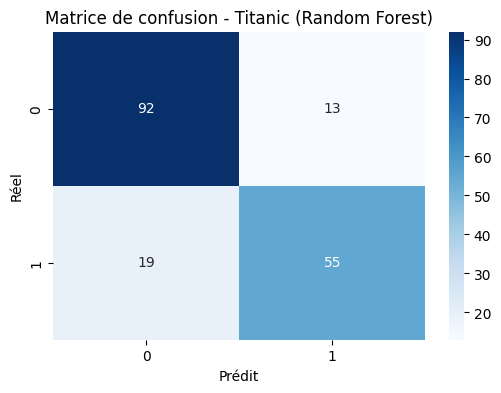

In [7]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calcul de la matrice pour le Random Forest
cm = confusion_matrix(y_test, y_pred_rf)

# Tracé de la heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matrice de confusion - Titanic (Random Forest)')
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.show()